# HW4 – Numerical greeks: finite-difference scheme and bump type

`Pricer` gets two class variables, `fd_method` (forward / backward / central) and `bump_type`
(absolute / relative), using two new enums. Delta and gamma are implemented for all combinations.
Below, the numerical greeks are compared with the analytic ones, absolute and relative bumping are
compared, and bump sizes are suggested.

The analytic greeks come from `EuropeanAnalyticPricer`. `BSVolModel` is used so that the volatility
does not change when the spot is bumped.

AI usage: Claude Opus 5.5 was used for helping with the code and interpretation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from market_data import *
MarketData.initialize()
from pricer import *

STOCK = list(Stock)[0]          # any underlying from the market data
S0 = MarketData.get_spot()[STOCK]
print('underlying:', STOCK.value, '| spot:', S0, '| rate:', MarketData.get_risk_free_rate())

underlying: TEST_COMPANY | spot: 100.0 | rate: 0.05


## Helpers

* `make_pricer` builds a pricer for a European option; `spot_scale` multiplies both spot and strike
  (used in section 4).
* `bump_greek` computes delta or gamma numerically with a chosen scheme, bump type and bump size.

In [2]:
def make_option(derivative_type, strike, expiry):
    return EuropeanContract(STOCK, derivative_type, LongShort.LONG, strike, expiry)


def make_pricer(derivative_type=PutCallFwd.CALL, strike=None, expiry=1.0, spot_scale=1.0):
    # strike is given in units of today's spot; e.g. 1.0 = ATM, 0.9 = 90% strike
    strike = 1.0 if strike is None else strike
    model = BSVolModel(STOCK)
    model.spot = S0 * spot_scale
    contract = make_option(derivative_type, strike * S0 * spot_scale, expiry)
    return EuropeanAnalyticPricer(contract, model, Params())


def analytic_greek(pricer, greek):
    return pricer.calc_delta(GreekMethod.ANALYTIC) if greek == 'delta' else pricer.calc_gamma(GreekMethod.ANALYTIC)


def bump_greek(pricer, greek, fd_method, bump_type, size):
    # size = fraction of spot (RELATIVE) or currency amount (ABSOLUTE)
    pricer.fd_method = fd_method
    pricer.bump_type = bump_type
    if bump_type == BumpType.RELATIVE:
        pricer.relative_bump_size = size
    else:
        pricer.absolute_bump_size = size
    return pricer.calc_delta(GreekMethod.BUMP) if greek == 'delta' else pricer.calc_gamma(GreekMethod.BUMP)


METHODS = list(FiniteDifferenceMethod)
COLORS = {FiniteDifferenceMethod.FORWARD: 'tab:blue',
          FiniteDifferenceMethod.BACKWARD: 'tab:orange',
          FiniteDifferenceMethod.CENTRAL: 'tab:green'}

## 1. All six combinations on one option

ATM call, 1 year. Bump: 1% of spot (relative) and 1 unit (absolute). The spot is 100, so both are
the same step and give the same numbers.

In [4]:
pricer = make_pricer(PutCallFwd.CALL, strike=1.0, expiry=1.0)
rows = []
for bump_type, size in [(BumpType.RELATIVE, 0.01), (BumpType.ABSOLUTE, 1.0)]:
    for m in METHODS:
        d = bump_greek(pricer, 'delta', m, bump_type, size)
        g = bump_greek(pricer, 'gamma', m, bump_type, size)
        rows.append([bump_type.value, m.value, d, g])
rows.append(['ANALYTIC', '', analytic_greek(pricer, 'delta'), analytic_greek(pricer, 'gamma')])
table1 = pd.DataFrame(rows, columns=['bump type', 'scheme', 'delta', 'gamma'])
table1

,bump type,scheme,delta,gamma
0,RELATIVE,FORWARD,0.630532,0.012384
1,RELATIVE,BACKWARD,0.617885,0.012904
2,RELATIVE,CENTRAL,0.624208,0.012647
3,ABSOLUTE,FORWARD,0.630532,0.012384
4,ABSOLUTE,BACKWARD,0.617885,0.012904
5,ABSOLUTE,CENTRAL,0.624208,0.012647
6,ANALYTIC,,0.624252,0.012648


## 2. Error on a set of European options (default bump, 1% relative)

Strikes 70%–130% of spot, maturities 0.1, 0.5, 1 and 2 years, calls and puts.
Error = |numerical − analytic|.

In [5]:
strikes = np.arange(0.70, 1.31, 0.05)
expiries = [0.1, 0.5, 1.0, 2.0]
records = []
for opt_type in (PutCallFwd.CALL, PutCallFwd.PUT):
    for T in expiries:
        for K in strikes:
            pr = make_pricer(opt_type, K, T)
            for greek in ('delta', 'gamma'):
                exact = analytic_greek(pr, greek)
                for m in METHODS:
                    num = bump_greek(pr, greek, m, BumpType.RELATIVE, 0.01)
                    records.append(dict(type=opt_type.value, T=T, K=K, greek=greek,
                                        scheme=m.value, numerical=num, analytic=exact,
                                        abs_error=abs(num - exact)))
errors = pd.DataFrame(records)

# summary: mean and max absolute error per greek and scheme, over all options
errors.groupby(['greek', 'scheme'])['abs_error'].agg(['mean', 'max']).style.format('{:.2e}')

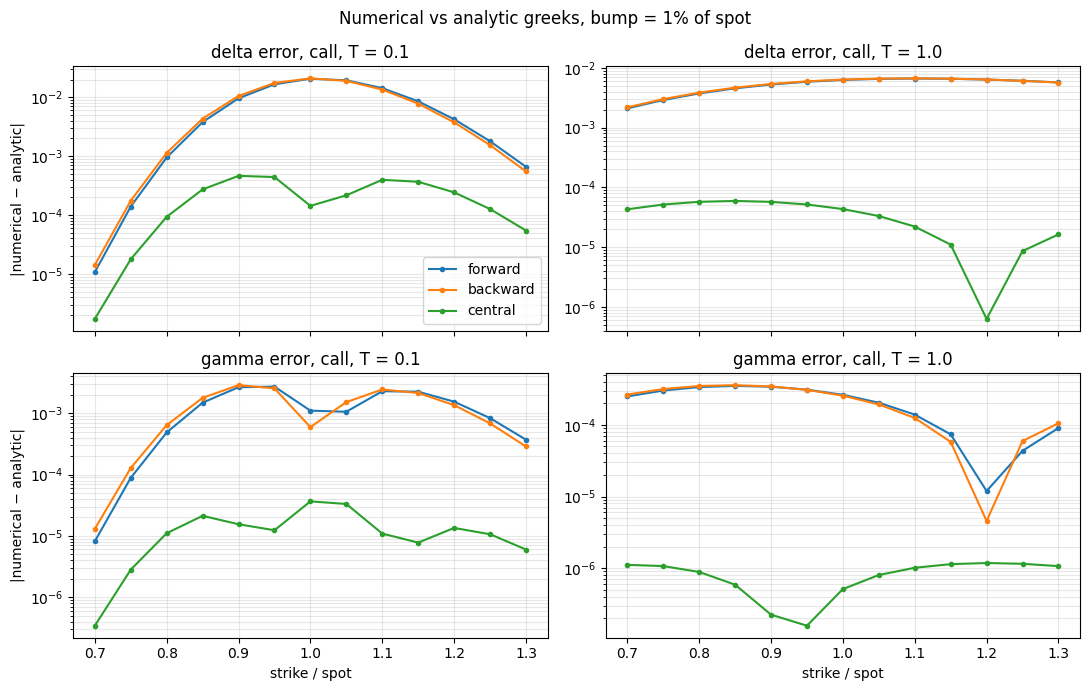

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for row, greek in enumerate(('delta', 'gamma')):
    for col, T in enumerate((0.1, 1.0)):
        ax = axes[row, col]
        sub = errors[(errors.type == 'CALL') & (errors.greek == greek) & (errors['T'] == T)]
        for m in METHODS:
            s = sub[sub.scheme == m.value]
            ax.semilogy(s.K, s.abs_error, 'o-', ms=3, color=COLORS[m], label=m.value.lower())
        ax.set_title(f'{greek} error, call, T = {T}')
        ax.grid(True, which='both', alpha=0.3)
        if row == 1: ax.set_xlabel('strike / spot')
        if col == 0: ax.set_ylabel('|numerical − analytic|')
axes[0, 0].legend()
fig.suptitle('Numerical vs analytic greeks, bump = 1% of spot')
plt.tight_layout(); plt.show()

**Reading the plot.**

* Central is much more accurate than forward/backward at the same bump size (roughly 100 times on
  average in the table above).
* Forward and backward have errors of about the same size.
* The errors are largest near the money and at short maturity.

## 3. Choosing the bump size

If the bump is too large, the difference quotient is a poor approximation of the derivative. If it
is too small, tiny rounding errors in the prices are divided by a tiny number and blow up. So the
error first falls and then rises as the bump shrinks; the best bump is at the minimum (dots on the plot).

Relative bump $h=\eta S$, with $\eta$ from $10^{-10}$ to $0.3$. ATM call, 1 year.

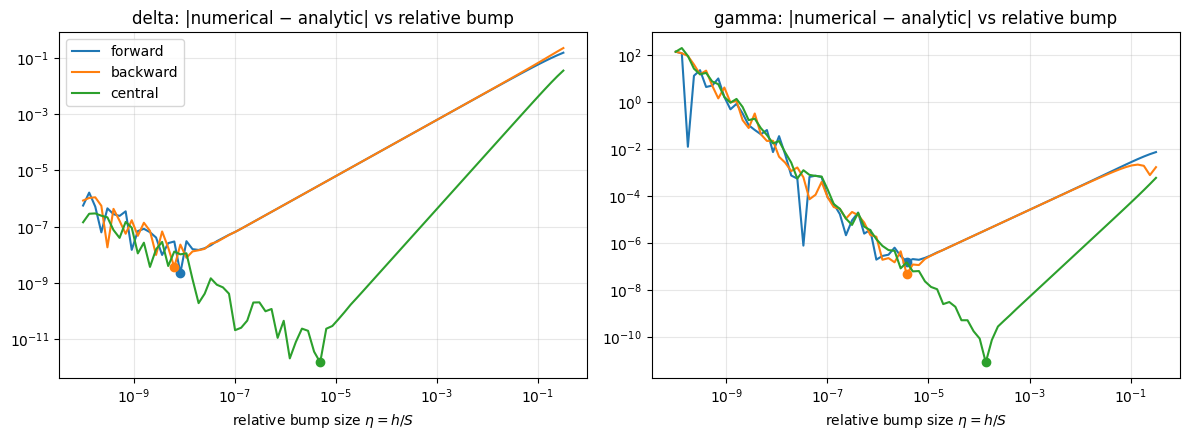

,greek,scheme,best eta,error at best eta
0,delta,FORWARD,8.4e-09,2.3e-09
1,delta,BACKWARD,6.4e-09,3.6e-09
2,delta,CENTRAL,4.9e-06,1.5e-12
3,gamma,FORWARD,3.7e-06,1.6e-07
4,gamma,BACKWARD,3.7e-06,4.7e-08
5,gamma,CENTRAL,1.4e-04,8.1e-12


In [7]:
etas = np.logspace(-10, -0.5, 80)

def error_curve(pricer, greek, m, bump_type, sizes):
    exact = analytic_greek(pricer, greek)
    return np.array([abs(bump_greek(pricer, greek, m, bump_type, h) - exact) for h in sizes])

pricer = make_pricer(PutCallFwd.CALL, 1.0, 1.0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
best = []
for ax, greek in zip(axes, ('delta', 'gamma')):
    for m in METHODS:
        err = error_curve(pricer, greek, m, BumpType.RELATIVE, etas)
        ax.loglog(etas, err, color=COLORS[m], label=m.value.lower())
        i = np.argmin(err)
        ax.plot(etas[i], err[i], 'o', color=COLORS[m])
        best.append([greek, m.value, etas[i], err[i]])
    ax.set_title(f'{greek}: |numerical − analytic| vs relative bump')
    ax.set_xlabel(r'relative bump size $\eta = h/S$'); ax.grid(True, which='both', alpha=0.3)
axes[0].legend()
plt.tight_layout(); plt.show()

pd.DataFrame(best, columns=['greek', 'scheme', 'best eta', 'error at best eta']).style.format(
    {'best eta': '{:.1e}', 'error at best eta': '{:.1e}'})

From the table, the best $\eta$ is about $10^{-8}$ for forward/backward delta, $5\cdot10^{-6}$ for
central delta, $4\cdot10^{-6}$ for forward/backward gamma and $10^{-4}$ for central gamma.

The same check for several options (central scheme only):

In [7]:
rows = []
for T in (0.1, 1.0, 2.0):
    for K in (0.8, 1.0, 1.2):
        pr = make_pricer(PutCallFwd.CALL, K, T)
        for greek in ('delta', 'gamma'):
            err = error_curve(pr, greek, FiniteDifferenceMethod.CENTRAL, BumpType.RELATIVE, etas)
            i = np.argmin(err)
            rows.append([T, K, greek, etas[i], err[i], err[np.argmin(abs(etas - 1e-2))]])
opt = pd.DataFrame(rows, columns=['T', 'K/S', 'greek', 'best eta (central)',
                                  'error at best', 'error at eta=1%'])
opt.style.format({'best eta (central)': '{:.1e}', 'error at best': '{:.1e}', 'error at eta=1%': '{:.1e}'})

,T,K/S,greek,best eta (central),error at best,error at eta=1%
0,0.100000,0.800000,delta,4.9e-06,1.2e-11,7.0e-05
1,0.100000,0.800000,gamma,7.8e-05,9.9e-10,8.2e-06
2,0.100000,1.000000,delta,2.1e-06,2.8e-12,1.1e-04
3,0.100000,1.000000,gamma,4.5e-05,3.6e-11,2.7e-05
4,0.100000,1.200000,delta,9.3e-07,7.6e-13,1.8e-04
5,0.100000,1.200000,gamma,4.5e-05,5.8e-10,1.0e-05
6,1.000000,0.800000,delta,9.3e-07,1.0e-12,4.3e-05
7,1.000000,0.800000,gamma,3.4e-05,6.3e-11,6.6e-07
8,1.000000,1.000000,delta,4.9e-06,1.5e-12,3.2e-05
9,1.000000,1.000000,gamma,1.4e-04,8.1e-12,3.8e-07


The best $\eta$ changes somewhat from option to option (about $4\cdot10^{-7}$–$1.5\cdot10^{-5}$ for
delta and $3\cdot10^{-5}$–$2.4\cdot10^{-4}$ for gamma), but the 1% default already gives errors below
$2\cdot10^{-4}$ for all of them.

## 4. Absolute vs relative bumping

The same ATM 1-year call at spot 1, 100 and 10 000 (strike scaled with it). Relative error of central
delta and gamma, plotted against the absolute bump $h$ (left) and against $h/S$ (right).

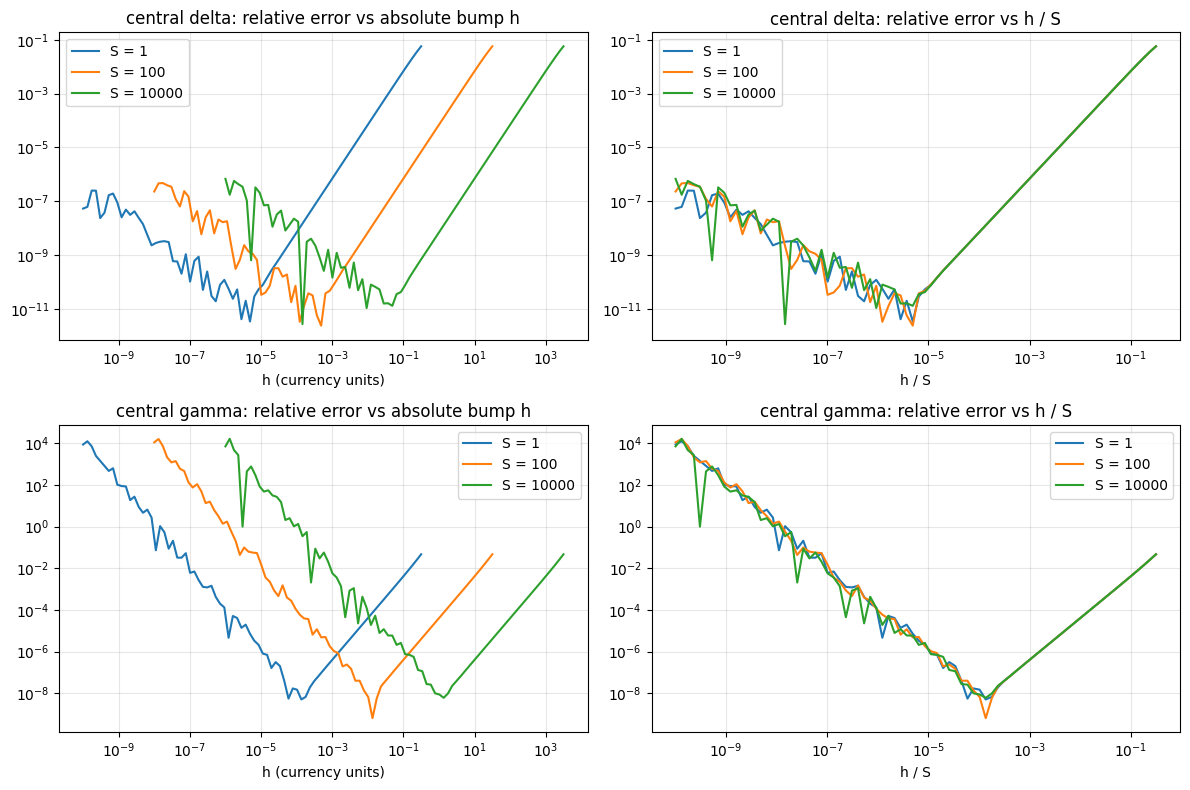

In [8]:
scales = [0.01, 1.0, 100.0]          # spot levels S0*scale
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, greek in enumerate(('delta', 'gamma')):
    for lam in scales:
        pr = make_pricer(PutCallFwd.CALL, 1.0, 1.0, spot_scale=lam)
        S = S0 * lam
        h_abs = etas * S                      # same grid of h/S, expressed in currency
        exact = analytic_greek(pr, greek)
        err = error_curve(pr, greek, FiniteDifferenceMethod.CENTRAL, BumpType.ABSOLUTE, h_abs) / abs(exact)
        axes[row, 0].loglog(h_abs, err, label=f'S = {S:g}')
        axes[row, 1].loglog(etas, err, label=f'S = {S:g}')
    axes[row, 0].set_title(f'central {greek}: relative error vs absolute bump h')
    axes[row, 1].set_title(f'central {greek}: relative error vs h / S')
    axes[row, 0].set_xlabel('h (currency units)'); axes[row, 1].set_xlabel('h / S')
    for ax in axes[row]: ax.grid(True, which='both', alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

In [3]:
# A fixed absolute bump of 1 unit vs a fixed relative bump of 1%, at different spot levels
rows = []
for lam in (0.05, 0.1, 1.0, 10.0, 100.0):
    pr = make_pricer(PutCallFwd.CALL, 1.0, 1.0, spot_scale=lam)
    for greek in ('delta', 'gamma'):
        exact = analytic_greek(pr, greek)
        e_abs = abs(bump_greek(pr, greek, FiniteDifferenceMethod.CENTRAL, BumpType.ABSOLUTE, 1.0) - exact) / abs(exact)
        e_rel = abs(bump_greek(pr, greek, FiniteDifferenceMethod.CENTRAL, BumpType.RELATIVE, 0.01) - exact) / abs(exact)
        rows.append([S0 * lam, greek, e_abs, e_rel])
pd.DataFrame(rows, columns=['spot', 'greek', 'rel. error, h = 1 (absolute)',
                            'rel. error, h = 1% S (relative)']).style.format(
    {'spot': '{:g}', 'rel. error, h = 1 (absolute)': '{:.1e}', 'rel. error, h = 1% S (relative)': '{:.1e}'})

,spot,greek,"rel. error, h = 1 (absolute)","rel. error, h = 1% S (relative)"
0,5,delta,2.6e-02,6.9e-05
1,5,gamma,1.7e-02,4.0e-05
2,10,delta,6.8e-03,6.9e-05
3,10,gamma,4.1e-03,4.0e-05
4,100,delta,6.9e-05,6.9e-05
5,100,gamma,4.0e-05,4.0e-05
6,1000,delta,6.9e-07,6.9e-05
7,1000,gamma,4.0e-07,4.0e-05
8,10000,delta,6.9e-09,6.9e-05
9,10000,gamma,2.6e-09,4.0e-05


**Reading the plots.** On the left the curves are shifted copies of each other; on the right they
lie on top of each other. So what matters is $h/S$, i.e. the relative bump.

In the table, the 1% relative bump gives the same error at every spot level. The absolute bump
$h=1$ is bad at a low spot (2.6% error at spot 5, where it is a 20% move) and very good at a high
spot, so it would have to be retuned for every underlying.

## 5. Conclusions

1. **Scheme:** use central differences. They are much more accurate than forward/backward at the
   same number of revaluations.
2. **Bump type:** use relative bumps. The accuracy is then the same for every underlying,
   whatever its price level.
3. **Bump size** (relative, $\eta=h/S$): about $5\cdot10^{-6}$ for central delta and $10^{-4}$ for
   central gamma. The 1% default is far from optimal, but accurate enough in practice
   (errors below $2\cdot10^{-4}$ in section 3).